# CS342 Coursework

In this coursework the aim is to predict a classification for 'degredation_status' which can be ('Normal', 'Moderate', 'Severe', 'Critical') 

## Predicting Battery Useful Life

In [12]:
# setup and libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# import data
battery_metadata = pd.read_csv('battery_metadata.csv')
battery_observations = pd.read_csv('battery_observations.csv')
training_data = pd.read_csv('train_batteries.csv')
validation_data = pd.read_csv('validation_batteries.csv')
test_data = pd.read_csv('test_batteries.csv')

# remove unallowed variables
battery_observations.drop(columns=['remaining_useful_cycles', 'remaining_useful_efc', 'state_of_health_pct'], inplace=True)

# join data
battery_data = battery_observations.merge(battery_metadata, on='battery_id')

# change oel_reached to binary values (0 or 1)
battery_data['eol_reached'] = battery_data['eol_reached'].map({True: 1, False: 0})

### Task 1: Exploratory Data Analysis and Data Visualisation

Analyse the correlation between features using a heatmap, only using upper triangle since it is symmetric. This plot allows us to look at relationships between covariates and find multicollinearity within the data.

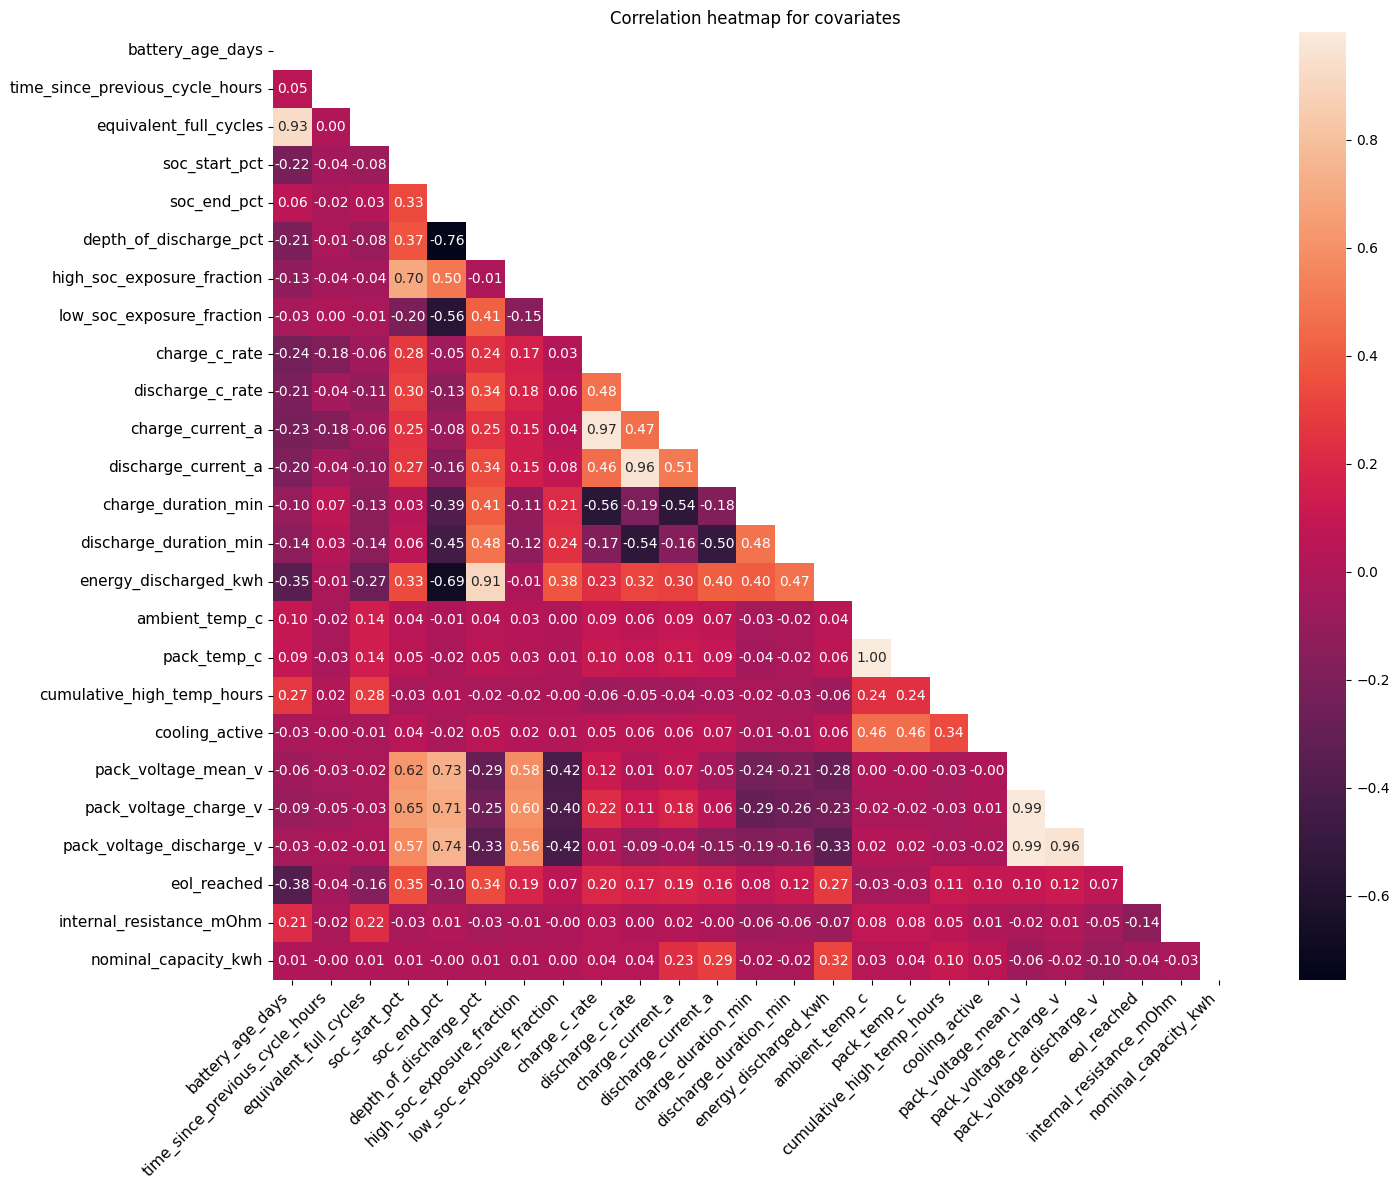

In [13]:
# analyse the correlation between features 
correlation_matrix = battery_data.drop(columns=['battery_id', 'timestamp', 'cycle_index']).select_dtypes('number').corr()
upper_triangle_mask = np.triu(np.ones_like(correlation_matrix, dtype='bool'))

# plot the corr map
plt.figure(figsize=(15,12))
sns.heatmap(correlation_matrix, mask=upper_triangle_mask, annot=True, fmt='.2f') # plot upper triangle correlation heatmap
plt.xticks(rotation=45, ha='right', fontsize=11) # rotate labels to make the plot smaller
plt.yticks(fontsize=11)
plt.title(label='Correlation heatmap for covariates')
plt.tight_layout()
plt.savefig('corr_heatmap.png', dpi=800, bbox_inches='tight')
plt.show()

The correlation heatmap indicates some multicollinearity in the data. The most obvious example being 'pack_voltage_mean_v' having a 0.99 correlation coefficient to 'pack_voltage_charge_v' and 'pack_voltage_discharge_v'.

The standard practice to deal with multicollinearity is to combine some of the covariates into a single feature for the model or to account for it using regularization in the model.

Distribtution of covariates based on target feature.

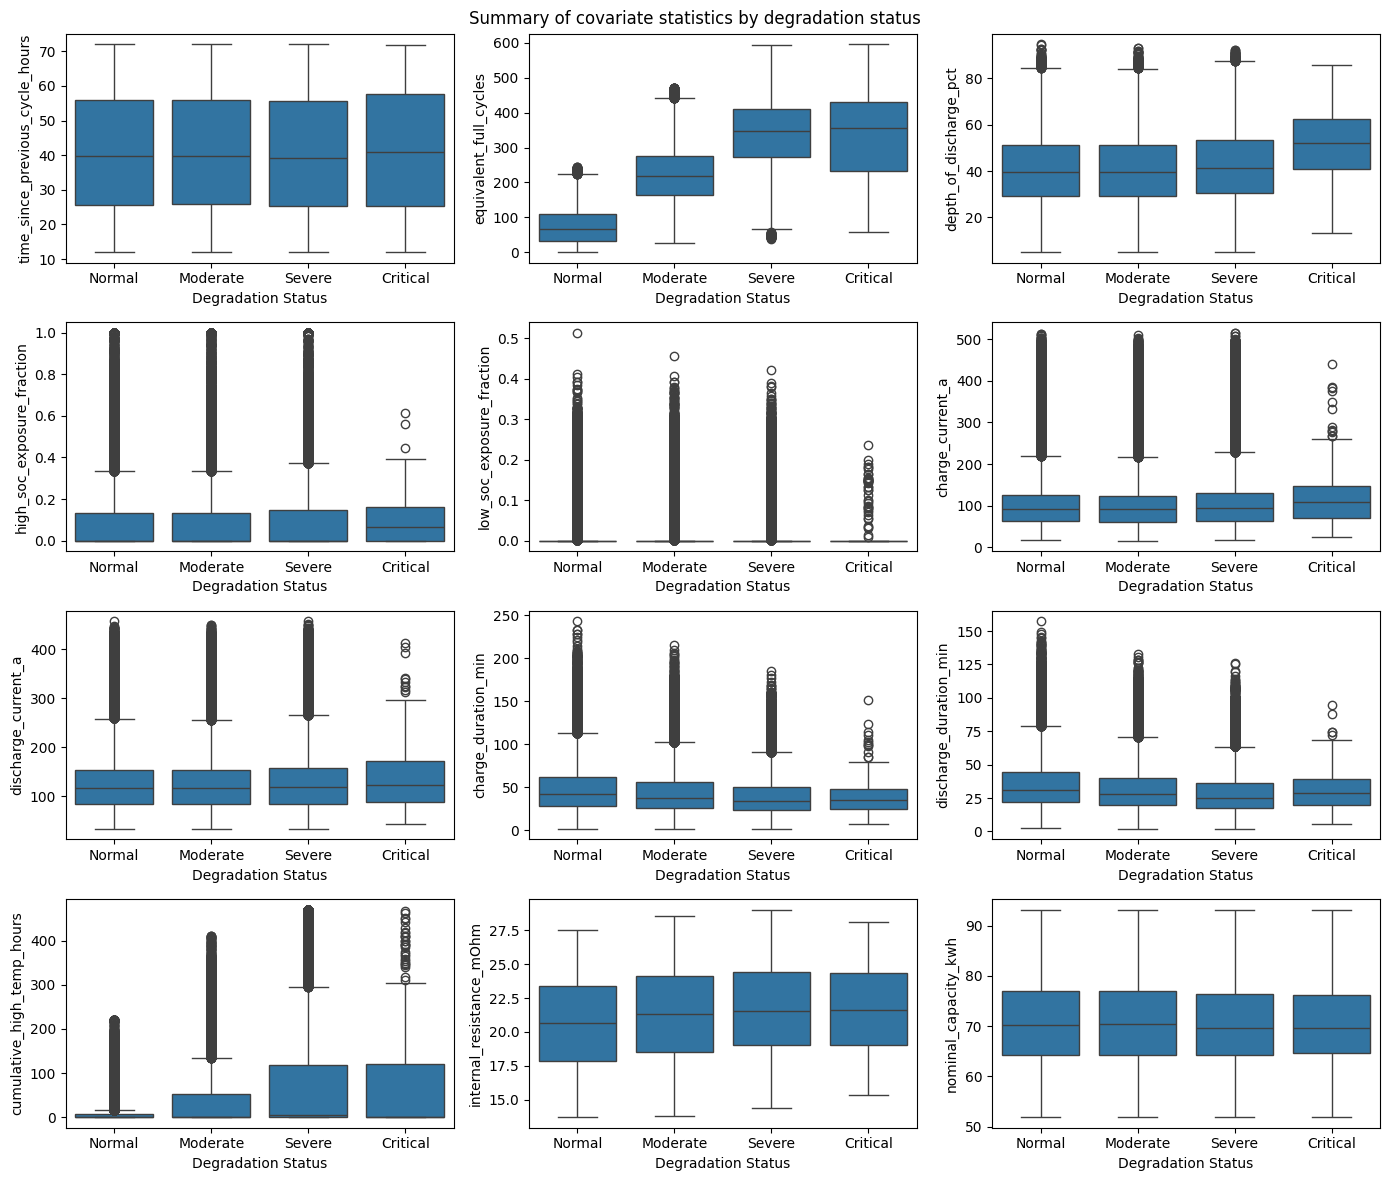

In [17]:
target_feature = 'degradation_status'
# look at covariates which might have impact of target feature
covariates_to_plot = [
    'time_since_previous_cycle_hours',
    'equivalent_full_cycles',
    'depth_of_discharge_pct',
    'high_soc_exposure_fraction',
    'low_soc_exposure_fraction',
    'charge_current_a',
    'discharge_current_a',
    'charge_duration_min',
    'discharge_duration_min',
    'cumulative_high_temp_hours',
    'internal_resistance_mOhm',
    'nominal_capacity_kwh'
]

# matplotlib figure with multiple subplots
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(14, 12))
axes = axes.flatten() # easier to iterate over 1d array

for i, covariate in enumerate(covariates_to_plot):
    sns.boxplot(
        data=battery_data,
        x=target_feature,
        y=covariate,
        ax=axes[i]
    )

    # add title and labels to each plot
    axes[i].set_xlabel('Degradation Status')
    axes[i].set_ylabel(covariate)

fig.suptitle('Summary of covariate statistics by degradation status')
plt.tight_layout()
plt.savefig('covariate_analysis.png', dpi=800, bbox_inches='tight')
plt.show()

### Task 2: Unsupervised (Classic) Machine Learning for Battery Degradation Analysis

### Task 3: Supervised (Classic) Machine Learning for Battery Degradation Analysis

### Task 4: Unsupervised Deep Learning for Battery Degradation Analysis

### Task 5: Supervised Deep Learning for Battery Degradation Analysis